# Fourier Transform and Frequency-Domain Filtering

This notebook demonstrates the 2D Discrete Fourier Transform (DFT), frequency-spectrum visualization, and Ideal Low-Pass and High-Pass filtering.

**Learning goals**
- Transform a grayscale image from the spatial domain to the frequency domain.
- Shift the zero-frequency component to the spectrum center.
- Design circular Ideal LPF and HPF masks.
- Apply the masks and reconstruct the filtered images using the inverse DFT.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


## 1. Load a grayscale image

The original exercise used a local `Camerama.png` image. To make the notebook portable, it first tries that filename and otherwise uses scikit-image's built-in camera image.

Loaded: /content/images/camera_man.png


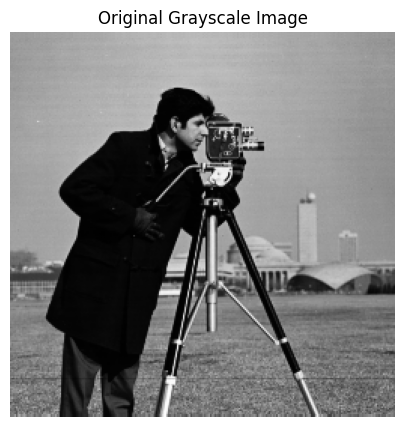

Image shape: (256, 256)


In [2]:
image_path = "/content/images/camera_man.png"
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    from skimage import data
    img = data.camera()
    img = np.asarray(img, dtype=np.uint8)
    print("Cameraman.png was not found; using the built-in camera image.")
else:
    print(f"Loaded: {image_path}")

plt.figure(figsize=(6, 5))
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()
print("Image shape:", img.shape)


## 2. Compute the 2D DFT and visualize the magnitude spectrum

The Fourier transform represents image information as spatial frequencies. `fftshift` moves the low-frequency components to the center for easier visualization.

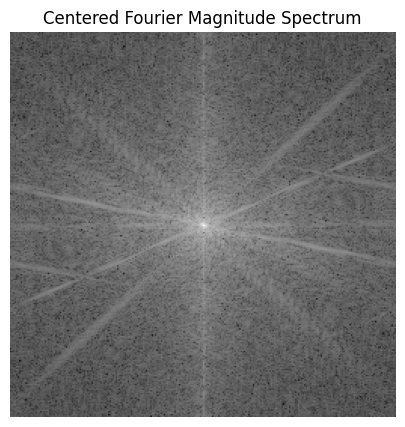

In [3]:
dft = cv2.dft(np.float32(img), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))
magnitude = cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
magnitude_spectrum = 20 * np.log(magnitude + 1)

plt.figure(figsize=(7, 5))
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Centered Fourier Magnitude Spectrum")
plt.axis("off")
plt.show()


## 3. Create Ideal Low-Pass and High-Pass filters

The LPF keeps frequencies inside a circle of radius `cutoff_radius`; the HPF removes that central circle and keeps higher frequencies.

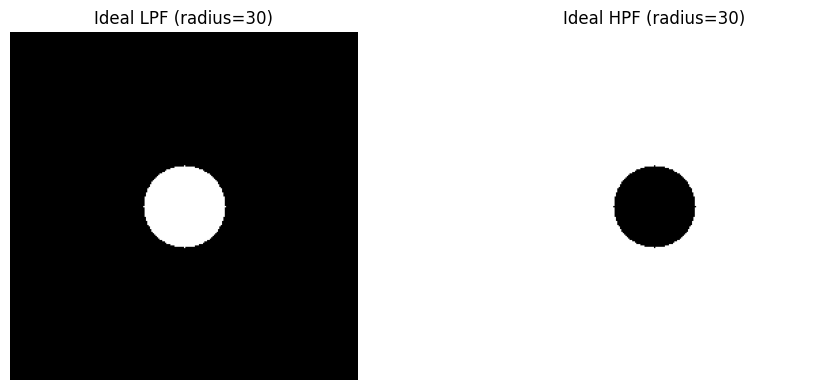

In [4]:
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
cutoff_radius = 30

y, x = np.ogrid[:rows, :cols]
distance = np.sqrt((x - ccol) ** 2 + (y - crow) ** 2)
lpf_mask = (distance <= cutoff_radius).astype(np.float32)
hpf_mask = 1.0 - lpf_mask

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(lpf_mask, cmap="gray")
plt.title(f"Ideal LPF (radius={cutoff_radius})")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(hpf_mask, cmap="gray")
plt.title(f"Ideal HPF (radius={cutoff_radius})")
plt.axis("off")
plt.tight_layout()
plt.show()


## 4. Apply the filters and reconstruct the images

Each mask is applied to both complex DFT channels. The inverse shift and inverse DFT return the result to the spatial domain.

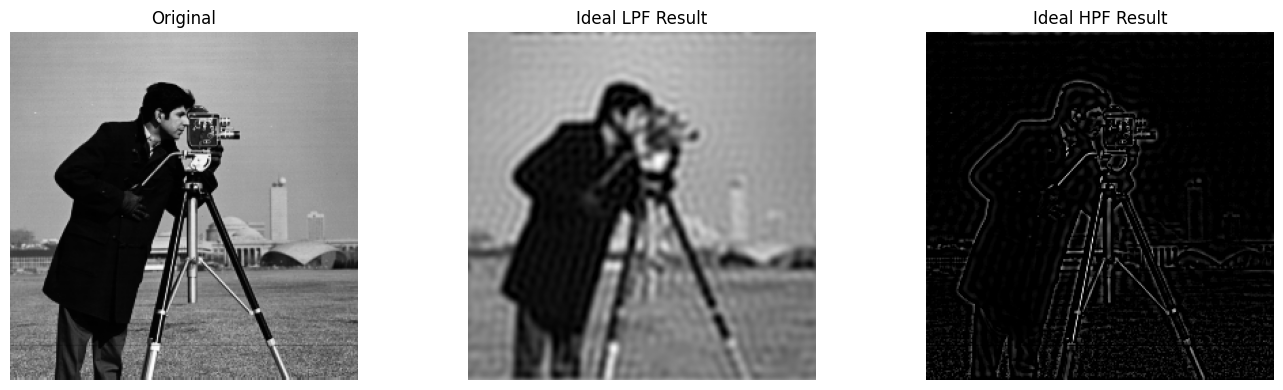

In [5]:
def inverse_filter(filtered_shifted_dft):
    unshifted = np.fft.ifftshift(filtered_shifted_dft, axes=(0, 1))
    reconstructed = cv2.idft(unshifted, flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT)
    return np.clip(reconstructed, 0, 255).astype(np.uint8)

lpf_dft = dft_shift * lpf_mask[:, :, np.newaxis]
hpf_dft = dft_shift * hpf_mask[:, :, np.newaxis]

img_lpf = inverse_filter(lpf_dft)
img_hpf = inverse_filter(hpf_dft)

plt.figure(figsize=(14, 4))
for i, (image, title) in enumerate([
    (img, "Original"), (img_lpf, "Ideal LPF Result"), (img_hpf, "Ideal HPF Result")
], start=1):
    plt.subplot(1, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()


## 5. Experiment with the cutoff radius

Try smaller and larger cutoff radii. A smaller LPF radius keeps fewer low frequencies and produces stronger smoothing. The HPF emphasizes fine details and edges while suppressing slowly varying intensity information.

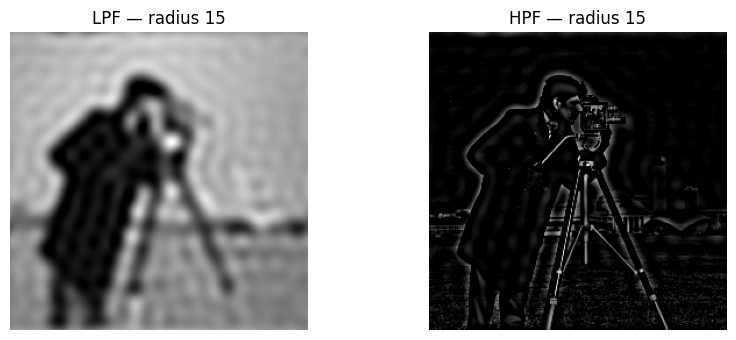

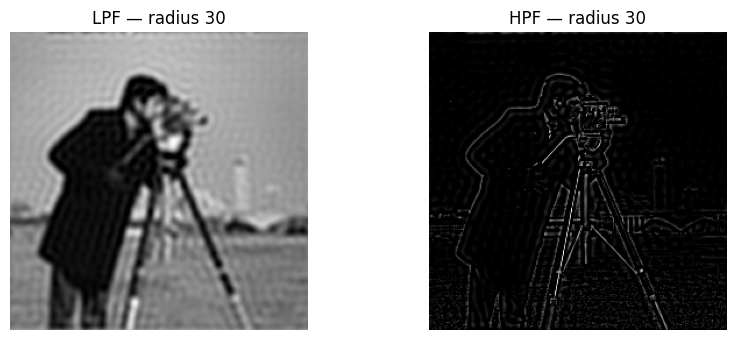

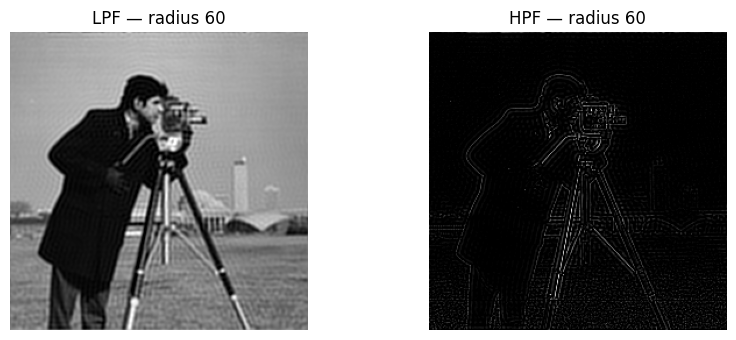

In [6]:
def apply_ideal_filters(image, radius):
    spectrum = cv2.dft(np.float32(image), flags=cv2.DFT_COMPLEX_OUTPUT)
    shifted = np.fft.fftshift(spectrum, axes=(0, 1))
    h, w = image.shape
    cy, cx = h // 2, w // 2
    yy, xx = np.ogrid[:h, :w]
    dist = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2)
    low_mask = (dist <= radius).astype(np.float32)
    high_mask = 1.0 - low_mask
    low_result = inverse_filter(shifted * low_mask[:, :, None])
    high_result = inverse_filter(shifted * high_mask[:, :, None])
    return low_result, high_result

for radius in (15, 30, 60):
    low, high = apply_ideal_filters(img, radius)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].imshow(low, cmap="gray")
    axes[0].set_title(f"LPF — radius {radius}")
    axes[1].imshow(high, cmap="gray")
    axes[1].set_title(f"HPF — radius {radius}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## Key observations
- Low-pass filtering preserves low-frequency content such as broad intensity regions and suppresses high-frequency details, resulting in smoothing.
- High-pass filtering suppresses low-frequency content and emphasizes rapid intensity changes such as edges and fine details.
- The cutoff radius controls how much frequency information is retained or removed.
- Ideal filters have an abrupt cutoff, which can introduce ringing artifacts near sharp transitions.